# Modelo propio: ponderación por regiones con MAP-EM

**Proyecto Final – Tercer Entregable · Machine Learning · Telco Customer Churn**

Este capítulo documenta el modelo original: la limitación que lo motiva, su formulación, la derivación de los pasos E y M, la propiedad teórica con su demostración, el pseudocódigo, la complejidad, la implementación propia, las pruebas unitarias y los pilotos exploratorios.

```{admonition} Estado al 2026-11-07
:class: note
- **Datos:** el dataset del proyecto, `WA_Fn-UseC_-Telco-Customer-Churn.csv`, **solo el conjunto de desarrollo** (5634 clientes de `train_index.csv`). El hold-out (1409 clientes de `test_index.csv`) no se usa en este capítulo.
- **R1 (novedad):** la búsqueda en WoS, Scopus, Scopus AI y Google Académico no encontró este mecanismo aplicado a churn (matriz de novedad en el Sheet *Candidatos_a_investigar*).
- **R2 (implementación propia):** clase `RegionalMAPEM` en `src/original_model.py`; el núcleo usa solo numpy y scipy; 9 pruebas pytest.
- **R3 (superioridad):** en el piloto exploratorio el modelo le gana con las tres pruebas (Holm) a 7 de 9 benchmarks; frente a HistGB y a la logística con splines, el mejor benchmark, solo Wilcoxon es significativo. Se espera reportar R3 como no alcanzado (tope 4.0), con su análisis.
- Los pilotos son **exploratorios**. El experimento confirmatorio se corre después de fijar `experiments/protocolo.md` con su tag de git.
```

## 1. Configuración

In [1]:
import sys, time, subprocess, inspect, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from src import original_model as om
from src.original_model import RegionalMAPEM, map_em, log_posterior

from sklearn.base import TransformerMixin, BaseEstimator
SEMILLA = 42                                              # semilla raíz del proyecto
SEED_ROLES = {'subset': 11, 'outer': 23, 'inner': 37, 'sampler': 41, 'model': 53, 'calibration': 67, 'test': 79, 'optimizer': 83}
def seed_for(role, *coordenadas):                         # misma derivación de semillas que CODIGO_EXPERIMENTO.ipynb
    return int(np.random.SeedSequence([SEMILLA, SEED_ROLES[role], *coordenadas]).generate_state(1)[0])

PILOTO = ROOT / "experiments" / "pilotos" / "piloto_kaggle" / "resultados"           # resultados del piloto exploratorio (2026-11-07)
raw = pd.read_csv(ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv"); raw.columns = raw.columns.str.strip()
train_ids = pd.read_csv(ROOT / "train_index.csv")["train_index"].astype(int).to_numpy()
test_ids = pd.read_csv(ROOT / "test_index.csv")["test_index"].astype(int).to_numpy()
assert set(train_ids).isdisjoint(test_ids)
X = raw.loc[train_ids].drop(columns=["customerID", "Churn"]).copy()      # SOLO desarrollo: el hold-out no se toca
y = raw.loc[train_ids, "Churn"].map({"No": 0, "Yes": 1}).astype(int).to_numpy()
del raw

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "AvgChargePerMonth"]
SERVICE = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]

class HistoricalFeatures(TransformerMixin, BaseEstimator):
    # ETL por filas del proyecto (no aprende nada): TotalCharges, servicios y AvgChargePerMonth
    def fit(self, X, y=None): return self
    def transform(self, X):
        out = X.copy(); total = pd.to_numeric(out["TotalCharges"], errors="coerce")
        if (total.isna() & out["tenure"].ne(0)).any(): raise ValueError("TotalCharges ausente con tenure != 0")
        out["TotalCharges"] = total.fillna(0.0)
        for c in SERVICE: out[c] = out[c].replace("No internet service", "No")
        out["MultipleLines"] = out["MultipleLines"].replace("No phone service", "No")
        avg = out["MonthlyCharges"].to_numpy(float).copy()
        np.divide(out["TotalCharges"].to_numpy(float), out["tenure"].to_numpy(float), out=avg, where=out["tenure"].to_numpy() > 0)
        out["AvgChargePerMonth"] = avg
        return out
print(f"Desarrollo: {X.shape[0]} clientes, {X.shape[1]} variables · tasa de churn = {y.mean():.3f} · hold-out excluido: {len(test_ids)} clientes")

Desarrollo: 5634 clientes, 19 variables · tasa de churn = 0.265 · hold-out excluido: 1409 clientes


Se usa el dataset del proyecto (versión de Kaggle, 7043 × 21) con el mismo ETL por filas del entregable anterior (`HistoricalFeatures`) y el mismo preprocesamiento (`StandardScaler` + `OneHotEncoder(drop='first')`), ajustado dentro de cada pliegue. Solo se usa el conjunto de desarrollo: el hold-out queda reservado para la evaluación final, como fija el protocolo.

## 2. Motivación: la limitación identificada

Los ensambles de churn de la literatura (Khoh et al., 2023; MetaLight-ChurnNet, 2026) y el stacking lineal combinan los modelos con **un único vector de pesos global**. Con eso suponen implícitamente que la fiabilidad relativa de cada modelo es la misma para todos los clientes.

**Hipótesis:** la fiabilidad relativa de los modelos cambia según el tipo de cliente. Si es así, una combinación con pesos por región debería poder aprovecharlo.

La evidencia empírica está en la sección 9. Que el mejor experto cambie entre regiones no basta: con expertos casi empatados, el ganador de cada región cambia también por azar. Una prueba de permutación de las regiones (piloto 8, sobre los 25 pliegues de desarrollo) muestra que la heterogeneidad existe, pero es débil. Los pesos por región ganan 0,0013 de log-verosimilitud por cliente frente a los globales, el doble de lo que ganan con regiones permutadas al azar (0,0007), y el resultado es significativo al 5 % en 15 de 25 pliegues. Ese exceso sobre el azar, de unos 0,0006 y medido dentro de la muestra, es una cota de lo que las regiones pueden aportar fuera de ella, y anticipa una ganancia pequeña.

## 3. Formulación

Sea $\{(x_i, y_i)\}_{i=1}^{n}$ con $y_i \in \{0,1\}$, y sean $M$ expertos calibrados (los benchmarks), con probabilidades $p_m(x)$. Sean $K$ regiones con pertenencias suaves $r_k(x) \ge 0$ y $\sum_k r_k(x) = 1$. El modelo es

$$
p(y=1 \mid x) = \sum_{k=1}^{K} r_k(x) \sum_{m=1}^{M} \pi_{km}\, p_m(x), \qquad \pi_k \in \Delta^{M-1}.
$$ (eq-modelo)

Con $\ell_{im} = p_m(x_i)^{y_i}\,(1-p_m(x_i))^{1-y_i}$, la verosimilitud de la mezcla es $\prod_i \sum_k \sum_m r_{ik}\pi_{km}\ell_{im}$. Se usa un prior $\pi_k \sim \mathrm{Dirichlet}(\alpha_k)$ con

$$
\alpha_{km} = 1 + c\, g_m ,
$$ (eq-prior)

donde $g$ son los pesos globales (mismo EM con $K = 1$ y sin prior) y $c \ge 0$ es la intensidad del prior. El objetivo MAP es

$$
F(\pi) = \sum_{i=1}^{n} \log \sum_{k=1}^{K}\sum_{m=1}^{M} r_{ik}\,\pi_{km}\,\ell_{im} \;+\; \sum_{k,m} (\alpha_{km}-1)\log \pi_{km}.
$$ (eq-F)

**Decisiones de diseño:**
- **Expertos fijos:** se reutilizan los benchmarks ya calibrados y no se reentrenan. Esto diferencia el modelo de la mezcla de expertos clásica.
- **Regiones no supervisadas (regla del protocolo, sección 6):** las variables continuas (más de 2 valores distintos) se llevan a cuantiles normales, se proyectan sobre sus 2 primeras componentes principales y sobre ellas se ajusta un GMM propio, antes que los pesos.
- **Prior hacia los pesos globales:** una región con pocos clientes no puede alejarse mucho de la combinación global, lo que regulariza.
- **Predicciones fuera de pliegue:** $p_m(x_i)$ en el entrenamiento viene de una CV interna, sin fuga.

## 4. Derivación del EM

Se introduce la variable latente $z_i = (k, m)$: qué región y qué experto "explican" al cliente $i$.

**Paso E.** Responsabilidades con los pesos actuales $\pi^{(t)}$:

$$
q_{ikm} = \frac{r_{ik}\,\pi^{(t)}_{km}\,\ell_{im}}{\sum_{k'}\sum_{m'} r_{ik'}\,\pi^{(t)}_{k'm'}\,\ell_{im'}} .
$$ (eq-E)

**Paso M.** Se maximiza $Q(\pi) = \sum_{i,k,m} q_{ikm}\log \pi_{km} + \sum_{k,m}(\alpha_{km}-1)\log\pi_{km}$ sujeto a $\sum_m \pi_{km} = 1$ para cada $k$. El lagrangiano $Q(\pi) - \sum_k \lambda_k(\sum_m \pi_{km} - 1)$ da $\partial/\partial \pi_{km}$: $(\sum_i q_{ikm} + \alpha_{km} - 1)/\pi_{km} = \lambda_k$. Sumando sobre $m$ se despeja $\lambda_k$:

$$
\pi^{(t+1)}_{km} = \frac{\sum_i q_{ikm} + \alpha_{km} - 1}{\sum_i \sum_{m'} q_{ikm'} + \sum_{m'}(\alpha_{km'} - 1)} .
$$ (eq-M)

Con $\alpha_{km} \ge 1$ el numerador es no negativo, así que $\pi^{(t+1)}$ queda en el símplex. Con $c = 0$ y $K = 1$ se recupera la estimación de máxima verosimilitud de una mezcla con componentes fijos.

## 5. Propiedad teórica

```{prf:proposition} Concavidad, ascenso monótono y óptimo global
:label: prop-mapem
Supóngase que (S1) $\ell_{im} > 0$ para todo $i, m$; (S2) las regiones $r_{ik}$ están fijas durante el EM; (S3) $\alpha_{km} \ge 1$; y (S4) el punto de partida es estrictamente positivo, $\pi^{(0)}_{km} > 0$ para todo $k, m$. Entonces:
1. $F$ es cóncava sobre el conjunto convexo $\mathcal D = \Delta^{M-1} \times \cdots \times \Delta^{M-1}$.
2. El EM de {eq}`eq-E`–{eq}`eq-M` cumple $F(\pi^{(t+1)}) \ge F(\pi^{(t)})$ para todo $t$.
3. La sucesión $F(\pi^{(t)})$ converge al máximo **global** $F^\ast = \max_{\mathcal D} F$, y todo punto límite de $\pi^{(t)}$ es un maximizador global de $F$ en $\mathcal D$.
```

**Demostración.**

1. Para cada $i$, $s_i(\pi) = \sum_{k,m} r_{ik}\ell_{im}\pi_{km}$ es afín en $\pi$ y, por (S1), positiva en $\mathcal D$. Como $\log$ es cóncava y no decreciente, $\log s_i(\pi)$ es cóncava. Por (S3), $(\alpha_{km} - 1)\log \pi_{km}$ es cóncava (o nula). La suma de funciones cóncavas es cóncava, y $\mathcal D$ es un producto de símplex, que es convexo.
2. Por la desigualdad de Jensen, para cualquier distribución $q_i$ sobre $(k,m)$: $\log s_i(\pi) \ge \sum_{k,m} q_{ikm}\log\big(r_{ik}\pi_{km}\ell_{im}/q_{ikm}\big)$. La igualdad se alcanza en $\pi^{(t)}$ cuando $q$ es {eq}`eq-E`. El paso M maximiza esa cota inferior más el log-prior (el problema es cóncavo y {eq}`eq-M` es su solución exacta por KKT). Por tanto $F(\pi^{(t+1)}) \ge \text{cota}(\pi^{(t+1)}) \ge \text{cota}(\pi^{(t)}) = F(\pi^{(t)})$ (Dempster, Laird y Rubin, 1977).
3. *Convergencia de los valores.* Por (S1), $s_i(\pi) \ge \min_m \ell_{im} > 0$ en todo $\mathcal D$, porque $\sum_k r_{ik} = 1$ y $\sum_m \pi_{km} = 1$. Por tanto, $F$ solo vale $-\infty$ donde $\pi_{km} = 0$ con $\alpha_{km} > 1$. El conjunto de nivel $\mathcal L_0 = \{\pi \in \mathcal D : F(\pi) \ge F(\pi^{(0)})\}$ es cerrado, está dentro del compacto $\mathcal D$ y en él $F$ es continua. La sucesión $F(\pi^{(t)})$ es no decreciente (parte 2) y está acotada por $\max_{\mathcal L_0} F$, así que converge.

   *Puntos límite.* Se distinguen dos casos.

   **(a) $\alpha_{km} > 1$ para todo $k, m$.** En $\mathcal L_0$ cada $\pi_{km}$ está acotado lejos de 0, porque si no $F \to -\infty$. Entonces $\mathcal L_0$ queda en el interior relativo de $\mathcal D$, donde el mapa del EM es continuo. Por Wu (1983, teorema 2), todo punto límite es un punto estacionario de $F$ restringida a $\mathcal D$. En el interior relativo, la estacionariedad equivale a las condiciones KKT, y en un problema cóncavo (parte 1) todo punto KKT es un máximo global.

   **(b) Algún $\alpha_{km} = 1$**, por ejemplo con $c = 0$ o con un peso global $g_m = 0$. El óptimo puede estar en el borde del símplex. Ahí el resultado de Wu no basta: un punto fijo del EM con $\pi_{km} = 0$ no tiene por qué cumplir KKT, porque el paso M es multiplicativo,

   $$\pi^{(t+1)}_{km} = \frac{\pi^{(t)}_{km}\, \sum_i r_{ik}\ell_{im}/s_i(\pi^{(t)}) + \alpha_{km} - 1}{\sum_{m'}\big(\pi^{(t)}_{km'}\, \sum_i r_{ik}\ell_{im'}/s_i(\pi^{(t)}) + \alpha_{km'} - 1\big)},$$

   y una coordenada que vale 0 se queda en 0. Por eso hace falta (S4). Con $\pi^{(0)} > 0$, la fórmula anterior y (S1) implican que $\pi^{(t)}_{km} > 0$ para todo $t$ finito. Además, el término del prior equivale a observaciones ficticias: $(\alpha_{km} - 1)\log\pi_{km}$ es la log-verosimilitud, con peso $\alpha_{km} - 1 \ge 0$, de un "cliente" cuya función $s(\pi)$ es simplemente $\pi_{km}$. Así, $F$ es una log-verosimilitud ponderada de la misma forma, $\sum_j w_j \log(\text{función lineal y positiva de } \pi)$, y cada iteración del EM es un paso de minimización alternada de la divergencia I entre dos conjuntos convexos:
   - las distribuciones $q$ con marginal fija en los clientes;
   - el modelo $r_{ik}\pi_{km}\ell_{im}$ con $\pi$ en el producto de símplex.

   Para esta estructura, Csiszár y Tusnády (1984, teorema 3) demuestran que, desde un punto de partida estrictamente positivo, los valores convergen al óptimo: $F(\pi^{(t)}) \to F^\ast$. El mismo resultado, para el EM de pesos de mezcla con componentes fijas, está en Vardi, Shepp y Kaufman (1985, sección 3). Por continuidad de $F$ en $\mathcal L_0$, todo punto límite $\bar\pi$ cumple $F(\bar\pi) = F^\ast$, es decir, es un maximizador global. $\blacksquare$

   *Verificación numérica del caso (b):* `test_optimo_global_en_el_borde` construye un problema con $\alpha = 1$ cuyo óptimo tiene un peso nulo. Comprueba que el EM, partiendo de pesos uniformes, alcanza el mismo valor de $F$ que un optimizador independiente (Nelder-Mead) y lleva a 0 el peso del experto dañino.

**Plausibilidad de los supuestos en Telco:**
- (S1) se garantiza recortando las probabilidades a $[10^{-6}, 1 - 10^{-6}]$.
- (S2) se cumple por construcción: el GMM se ajusta antes y queda fijo.
- (S3) se cumple porque $c \ge 0$ y $g$ está en el símplex.
- (S4) se cumple por construcción: `map_em` parte de pesos uniformes $1/M$.

**Unicidad.** Si además $c > 0$ y $g_m > 0$ para todo $m$, entonces $\alpha_{km} > 1$ y cada término $(\alpha_{km}-1)\log\pi_{km}$ es estrictamente cóncavo, así que $F$ es estrictamente cóncava y el óptimo es **único**. Si algún $g_m = 0$ (en Telco varios expertos reciben peso global casi nulo) o $c = 0$, puede haber un conjunto de óptimos con el mismo valor de $F$; la convergencia al valor óptimo global se mantiene.

**Alcance:** la propiedad cubre la etapa de pesos. El GMM de regiones es otro EM, con su propio ascenso monótono, pero no es cóncavo: sus regiones dependen de la inicialización (k-means++ con semilla fija).

**Verificación numérica:** `test_log_posterior_nunca_baja`, `test_optimo_global_por_concavidad` y `test_optimo_global_en_el_borde` (sección 8), y el historial de $F$ en Telco (sección 9).

**Velocidad.** La proposición garantiza convergencia, pero no rapidez. El EM converge, como mucho, linealmente, y se vuelve lento cuando el óptimo tiene pesos cerca de 0 (caso b). Eso explica por qué, con 9 expertos, 500 iteraciones no alcanzaban la tolerancia de $10^{-9}$ en el piloto 6b, y por qué `max_iter` subió a 5000.

## 6. Algoritmo

```{prf:algorithm} RegionalMAPEM
:label: alg-mapem
**Entradas:** $X \in \mathbb R^{n\times p}$, $y \in \{0,1\}^n$, expertos $\{f_m\}_{m=1}^M$, $K$, $c$, pliegues internos $V$, tolerancia $\varepsilon$, $T_{\max}$.

**Salidas:** expertos calibrados reentrenados, regiones $(\mu, W, \text{GMM})$, pesos $\pi \in \mathcal D$.

1. Para $v = 1..V$: entrenar cada $f_m$ calibrado (Platt) en los pliegues $\neq v$ y predecir el pliegue $v$, lo que da $P^{\text{oof}} \in [0,1]^{n\times M}$.
2. Reentrenar cada $f_m$ calibrado con todo $X$.
3. Calcular $\ell_{im}$ a partir de $P^{\text{oof}}$ recortado a $[10^{-6}, 1-10^{-6}]$.
4. Tomar las columnas continuas de $X$, llevarlas a cuantiles normales $\Phi^{-1}(\text{rango}/(n+1))$, PCA por SVD con $d = 2$ componentes y estandarizar: $Z$.
5. GMM de $K$ componentes por EM (inicialización k-means++), lo que da $r_{ik}$.
6. Pesos globales $g$: EM con $K = 1$, $\alpha = 1$.
7. $\alpha_{km} \leftarrow 1 + c\,g_m$; $\pi^{(0)} \leftarrow 1/M$.
8. **Repetir:** paso E {eq}`eq-E`; paso M {eq}`eq-M`; **hasta** $F(\pi^{(t+1)}) - F(\pi^{(t)}) \le \varepsilon(1 + |F(\pi^{(t)})|)$ o $t = T_{\max}$.
9. **Predicción:** $\hat p(x) = \sum_k r_k(x)\sum_m \pi_{km} f_m(x)$.
```

## 7. Complejidad

| Etapa | Entrenamiento | Predicción ($n'$ clientes) |
|---|---|---|
| Expertos (CV interna + reentrenamiento) | $(V+1)\sum_m C_m(n)$ | $\sum_m C^{\text{pred}}_m(n')$ |
| PCA (SVD) | $O(n p^2)$ | $O(n' p d)$ |
| GMM ($T_g$ iteraciones, dimensión $d$) | $O(T_g\,(n K d^2 + K d^3))$ | $O(n' K d^2)$ |
| MAP-EM ($T$ iteraciones) | $O(T\, n K M)$ | $O(n' K M)$ |

El costo lo dominan los expertos. El aporte propio (GMM + MAP-EM) es lineal en $n$, $K$ y $M$ por iteración. La celda siguiente mide el tiempo del MAP-EM con un número fijo de iteraciones para comprobar la linealidad en $n$ y en $M$.

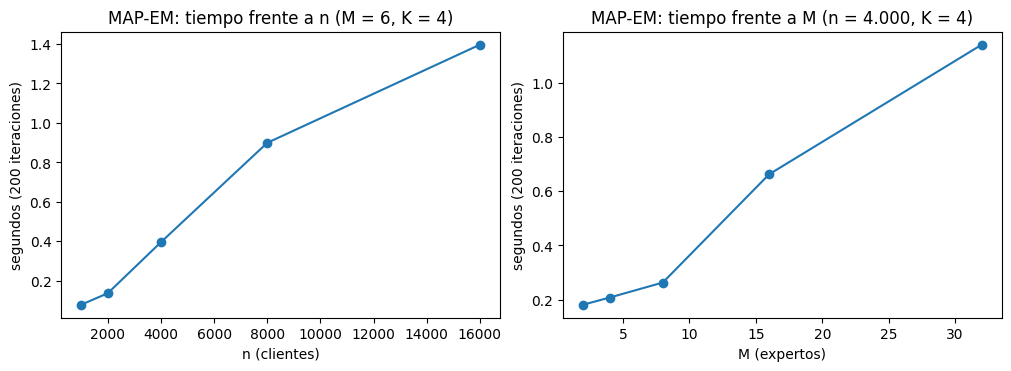

pendiente log-log en n: 1.10 · en M: 0.70 (1 = lineal)


In [2]:
rng = np.random.default_rng(SEMILLA)
def t_mapem(n, M, K=4, iters=200):
    Lik = rng.uniform(0.05, 0.95, (n, M)); R = rng.dirichlet(np.ones(K), n); a = np.ones((K, M))
    t0 = time.perf_counter(); map_em(Lik, R, a, max_iter=iters, tol=-np.inf); return time.perf_counter() - t0
ns = [1000, 2000, 4000, 8000, 16000]; Ms = [2, 4, 8, 16, 32]
tn = [np.median([t_mapem(n, 6) for _ in range(3)]) for n in ns]
tm = [np.median([t_mapem(4000, M) for _ in range(3)]) for M in Ms]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
ax[0].plot(ns, tn, "o-"); ax[0].set(xlabel="n (clientes)", ylabel="segundos (200 iteraciones)", title="MAP-EM: tiempo frente a n (M = 6, K = 4)")
ax[1].plot(Ms, tm, "o-"); ax[1].set(xlabel="M (expertos)", ylabel="segundos (200 iteraciones)", title="MAP-EM: tiempo frente a M (n = 4.000, K = 4)")
plt.show()
print("pendiente log-log en n: %.2f · en M: %.2f (1 = lineal)" % (np.polyfit(np.log(ns), np.log(tn), 1)[0], np.polyfit(np.log(Ms), np.log(tm), 1)[0]))

En $n$ la pendiente log-log es cercana a 1, lo que confirma el costo lineal. En $M$ sale por debajo de 1 porque, con pocos expertos, domina el costo fijo de las operaciones vectorizadas: $O(nKM)$ es la cota superior del costo por iteración, y la medición queda por debajo de ella.

## 8. Implementación y pruebas unitarias

La clase hereda de `BaseEstimator` y `ClassifierMixin`, así que funciona dentro de un `Pipeline`, con `clone` y con la validación anidada del Entregable 2. scikit-learn solo aporta la interfaz, la validación de entradas y los expertos (que son los benchmarks). La PCA, el GMM y el MAP-EM están programados en numpy y scipy.

In [3]:
print(inspect.getsource(om.map_em)); print(inspect.getsource(om.RegionalMAPEM.fit))

def map_em(Lik, R, alpha, max_iter=2000, tol=1e-8):
    """MAP-EM de los pesos por región. Lik: n x M verosimilitudes de los expertos; R: n x K.

    Paso E: q_ikm = r_ik pi_km l_im / sum_{k',m'} r_ik' pi_k'm' l_im'
    Paso M: pi_km = (sum_i q_ikm + alpha_km - 1) / (sum_i sum_m q_ikm + sum_m (alpha_km - 1))
    Devuelve (pi, historial de F, convergió).
    """
    K, M = R.shape[1], Lik.shape[1]
    pi = np.full((K, M), 1.0 / M)
    hist = [log_posterior(pi, Lik, R, alpha)]
    for _ in range(max_iter):
        mix = R[:, :, None] * pi[None] * Lik[:, None, :]
        q = mix / mix.sum(axis=(1, 2))[:, None, None]
        num = q.sum(axis=0) + alpha - 1
        pi = np.clip(num / num.sum(axis=1, keepdims=True), 1e-300, None)
        hist.append(log_posterior(pi, Lik, R, alpha))
        if hist[-1] - hist[-2] <= tol * (1 + abs(hist[-2])):
            return pi, np.array(hist), True
    return pi, np.array(hist), False

    def fit(self, X, y):
        X, y = check_X_y(X, y)
        self.

Pruebas (`tests/test_original_model.py`, 9 pruebas). Cubren los cinco puntos de la sección 5.4 de la guía: aprende, es reproducible, rechaza entradas inválidas, funciona con `clone` y cumple la propiedad teórica.

In [4]:
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "tests/test_original_model.py"], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-2500:])

## 9. Validación en Telco (exploratoria)

Validación sobre los **5 pliegues externos de la repetición 0** (`seed_for('outer', 0)`, los mismos del entregable anterior), con el ETL y el preprocesamiento dentro del pipeline. Los expertos son los 9 del piloto, sin SMOTE y calibrados con Platt, con hiperparámetros fijos; el modelo propio usa $K = 4$ y $c = 20$. El confirmatorio optimizará todos los hiperparámetros con el mismo presupuesto.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

def prepro():
    return Pipeline([("features", HistoricalFeatures()), ("prep", ColumnTransformer(
        [("num", StandardScaler(), NUMERIC), ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), CATEGORICAL)],
        remainder="drop", sparse_threshold=0.0))])
CONT = [0, 1, 2, 4]          # columnas continuas tras el preprocesamiento (tenure, MonthlyCharges, TotalCharges, AvgChargePerMonth)
EXPERTOS = [
    ("LR", LogisticRegression(max_iter=3000)),
    ("LR_splines", Pipeline([("spl", ColumnTransformer([("s", SplineTransformer(n_knots=5), CONT)], remainder="passthrough")),
                             ("lr", LogisticRegression(C=0.5, max_iter=4000))])),
    ("RF", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA)),
    ("XGB", XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=SEMILLA, verbosity=0)),
    ("HistGB", HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=SEMILLA)),
    ("kNN", KNeighborsClassifier(n_neighbors=50, weights="distance")),
    ("CatBoost", CatBoostClassifier(iterations=400, learning_rate=0.05, depth=4, verbose=0, random_seed=SEMILLA, thread_count=2)),
    ("LightGBM", LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA, verbose=-1)),
    ("NaiveBayes", GaussianNB())]

filas, modelos = [], []
outer = StratifiedKFold(5, shuffle=True, random_state=seed_for("outer", 0))
for f, (tr, te) in enumerate(outer.split(X, y)):
    pipe = Pipeline([("pre", prepro()), ("modelo", RegionalMAPEM(experts=EXPERTOS, n_regions=4, prior_strength=20, inner_cv=3,
                                                                 max_iter=5000, random_state=seed_for("inner", 0, f)))])
    pipe.fit(X.iloc[tr], y[tr]); m = pipe.named_steps["modelo"]; modelos.append((pipe, tr, te))
    Xte = pipe.named_steps["pre"].transform(X.iloc[te])
    P = {"RegionalMAPEM (propio)": m.predict_proba(Xte)[:, 1]} | {n: m.expert_proba(Xte)[:, j] for j, n in enumerate(m.expert_names_)}
    for nom, p in P.items():
        filas.append(dict(pliegue=f, modelo=nom, log_loss=log_loss(y[te], p), brier=brier_score_loss(y[te], p), auc=roc_auc_score(y[te], p)))
res = pd.DataFrame(filas)
tabla = res.groupby("modelo")[["log_loss", "brier", "auc"]].agg(["mean", "std"]).sort_values(("log_loss", "mean")).round(4)
tabla

log_loss           brier             auc        
                           mean     std    mean     std    mean     std
modelo                                                                 
RegionalMAPEM (propio)   0.4126  0.0105  0.1337  0.0047  0.8490  0.0108
LR_splines               0.4138  0.0109  0.1338  0.0045  0.8479  0.0107
HistGB                   0.4158  0.0110  0.1351  0.0050  0.8460  0.0112
LR                       0.4173  0.0095  0.1352  0.0040  0.8455  0.0093
LightGBM                 0.4176  0.0088  0.1354  0.0045  0.8440  0.0089
XGB                      0.4216  0.0141  0.1356  0.0062  0.8477  0.0107
RF                       0.4231  0.0125  0.1361  0.0057  0.8449  0.0096
CatBoost                 0.4254  0.0122  0.1367  0.0055  0.8447  0.0084
kNN                      0.4367  0.0101  0.1415  0.0044  0.8309  0.0095
NaiveBayes               0.4554  0.0134  0.1472  0.0050  0.8303  0.0097

Los expertos se evalúan dentro del mismo modelo ajustado, así que comparten exactamente el preprocesamiento, los pliegues y la calibración. Es una comparación pareada.

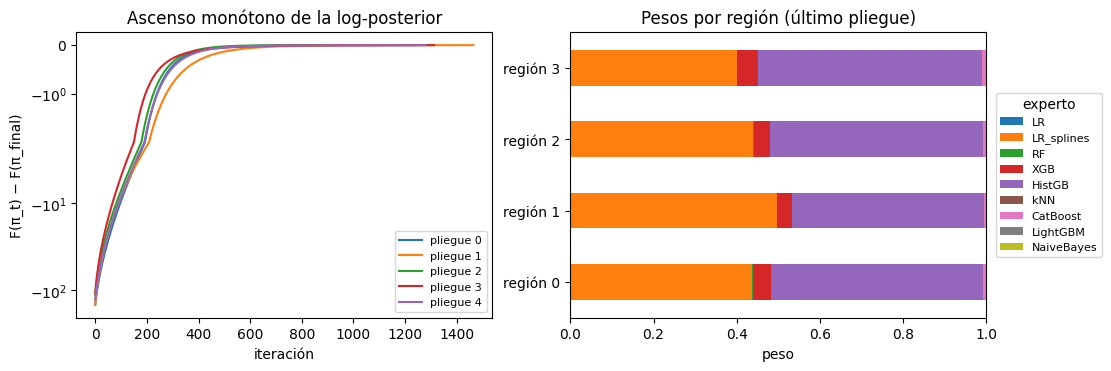

convergió en todos los pliegues: True · ascenso monótono: True


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for f, (pipe, _, _) in enumerate(modelos):
    h = pipe.named_steps["modelo"].history_
    ax[0].plot(h - h[-1], label=f"pliegue {f}")
ax[0].set(yscale="symlog", xlabel="iteración", ylabel="F(π_t) − F(π_final)", title="Ascenso monótono de la log-posterior"); ax[0].legend(fontsize=8)
m = modelos[-1][0].named_steps["modelo"]
pd.DataFrame(m.weights_, columns=m.expert_names_, index=[f"región {k}" for k in range(m.n_regions)]).plot.barh(stacked=True, ax=ax[1], legend=False)
ax[1].set(xlabel="peso", xlim=(0, 1), title="Pesos por región (último pliegue)"); ax[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, title="experto"); plt.show()
print("convergió en todos los pliegues:", all(p.named_steps["modelo"].converged_ for p, _, _ in modelos),
      "· ascenso monótono:", all(np.all(np.diff(p.named_steps["modelo"].history_) >= -1e-9) for p, _, _ in modelos))

### Evidencia de la limitación: la fiabilidad de los expertos cambia por región

La celda siguiente cuenta en cuántos pliegues cambia el mejor experto entre regiones duras. Ese conteo, por sí solo, no prueba nada: con regiones asignadas al azar el mejor experto también cambia, en promedio, en el 76 % de los casos. La prueba que separa la señal del azar está después de la celda.

In [7]:
filas = []
for f, (pipe, tr, _) in enumerate(modelos):
    m = pipe.named_steps["modelo"]; yt = y[tr]; reg = m.train_regions_.argmax(1); P = m.oof_proba_
    ll = -(yt[:, None] * np.log(P) + (1 - yt[:, None]) * np.log(1 - P))
    for k in range(m.n_regions):
        sel = reg == k
        if sel.sum() == 0: continue
        fila = dict(pliegue=f, region=k, n=int(sel.sum()), churn=yt[sel].mean())
        fila |= {n: ll[sel, j].mean() for j, n in enumerate(m.expert_names_)}
        filas.append(fila)
het = pd.DataFrame(filas); het["mejor experto"] = het[m.expert_names_].idxmin(axis=1)
print("pliegues en los que el mejor experto cambia entre regiones:",
      het.groupby("pliegue")["mejor experto"].nunique().gt(1).sum(), "de", het.pliegue.nunique())
het[het.pliegue == 0].round(3)

pliegues en los que el mejor experto cambia entre regiones: 5 de 5


,pliegue,region,n,churn,LR,LR_splines,RF,XGB,HistGB,kNN,CatBoost,LightGBM,NaiveBayes,mejor experto
0,0,0,1398,0.447,0.581,0.575,0.584,0.584,0.580,0.594,0.589,0.585,0.610,LR_splines
1,0,1,844,0.060,0.197,0.200,0.212,0.211,0.201,0.215,0.215,0.200,0.233,LR
2,0,2,1891,0.153,0.358,0.352,0.364,0.365,0.358,0.368,0.368,0.363,0.377,LR_splines
3,0,3,374,0.615,0.619,0.597,0.594,0.594,0.593,0.702,0.590,0.596,0.750,CatBoost


**Prueba de permutación de las regiones (piloto 8, `experiments/pilotos/piloto_heterogeneidad.py`).** En cada uno de los 25 pliegues de desarrollo se calcula

$$T = \frac{1}{n}\sum_i \log s_i(\hat\pi_{\text{regional}}) - \frac{1}{n}\sum_i \log s_i(\hat g),$$

la ganancia de log-verosimilitud por cliente de los pesos por región ($K = 4$, $c = 0$) frente a los pesos globales, con las predicciones fuera de pliegue de los expertos. Bajo $H_0$ (la fiabilidad relativa de los expertos no depende de la región), permutar entre clientes las filas de $R$ no cambia la distribución de $T$. Se usan $B = 200$ permutaciones y $p = (1 + \#\{T_{\text{perm}} \ge T\})/(B + 1)$.

| Medida | Valor |
|---|---|
| $T$ medio (regiones reales) | 0,00134 |
| $T$ medio con regiones permutadas | 0,00069 |
| Exceso sobre el azar | 0,00064 |
| Pliegues con $p < 0{,}05$ | 15 de 25 (se esperarían 1,25 bajo $H_0$) |
| $p$ mediano | 0,040 |
| Pliegues en que cambia el mejor experto: real / bajo $H_0$ | 24 de 25 / 76 % |

**Lectura.** Hay heterogeneidad regional real, pero pequeña: las regiones capturan, dentro de la muestra, unos 0,0006 de log-verosimilitud por cliente por encima de lo que capturaría una partición al azar. Fuera de la muestra, la ablación del piloto 6b da 0,0001, lo esperable cuando una señal tan débil se estima con unos 1100 clientes por región. Los pliegues no son independientes (comparten clientes), así que no se combinan sus valores $p$ en uno solo; el resultado se reporta como evidencia descriptiva. Esto explica por qué el prior hacia los pesos globales es necesario y por qué no se espera que las regiones, por sí solas, produzcan una superioridad significativa.

## 10. Pilotos exploratorios e iteraciones de diseño

La guía pide reportar cuántas iteraciones de diseño se evaluaron. Todas usan expertos calibrados con Platt, sin SMOTE, y log-loss como métrica.

| Iteración | Fecha | Datos | Qué cambió | Resultado |
|---|---|---|---|---|
| 0 | 2026-10-30 | IBM extendido | SVM+ (LUPI) con CLTV y Churn Score | F1 0,35 frente a 0,58 sin información privilegiada; riesgo de fuga y variables que no existen en el dataset del proyecto → **descartado** |
| 1–3 | 2026-11-03 | IBM extendido, 7043 clientes | MAP-EM por regiones, 7 reglas, 6–9 expertos | Empate con HistGB; solo Wilcoxon significativo |
| **4** | **2026-11-07** | **Dataset del proyecto, solo desarrollo (5634)** | **Repetición de la regla elegida con la regla de regiones del protocolo, 9 expertos y ablación** | **Ver tablas siguientes** |
| 5 | 2026-11-08 | Dataset del proyecto, solo desarrollo (5634) | Prueba de permutación de las regiones sobre los pliegues de la iteración 4 | Heterogeneidad real pero débil: exceso de 0,0006 sobre el azar; $p < 0{,}05$ en 15 de 25 pliegues (sección 9) |

```{admonition} Desviación declarada
:class: warning
Las iteraciones 0 a 3 se corrieron por error con `Telco_customer_churn.xlsx` (versión extendida de IBM) y con los 7043 clientes, incluido el hold-out. Ninguna cifra de esas iteraciones se usa en este capítulo ni en el protocolo. La iteración 4 repite el análisis con el dataset del proyecto y solo con el conjunto de desarrollo. Como el hold-out ya intervino en decisiones exploratorias de diseño (la elección de la familia), su evaluación final se reporta con esta advertencia.
```

Piloto de la iteración 4: 5 repeticiones × 5 pliegues externos (`seed_for('outer', r)`), cross-fitting interno de 3 pliegues para los pesos, 9 expertos con hiperparámetros fijos (código en `experiments/pilotos/piloto_kaggle/`).

In [8]:
resumen = pd.read_csv(PILOTO / "resumen.csv", header=[0, 1], index_col=0)
resumen.round(4)

log_loss           brier             auc          \
                              mean     std    mean     std    mean     std   
metodo                                                                       
Ablación: regiones duras    0.4116  0.0088  0.1333  0.0036  0.8500  0.0080   
RegionalMAPEM (K=4, c=20)   0.4116  0.0087  0.1333  0.0036  0.8500  0.0080   
Pesos globales EM (K=1)     0.4117  0.0086  0.1333  0.0035  0.8500  0.0080   
Stacking lineal             0.4117  0.0100  0.1334  0.0040  0.8496  0.0082   
Ablación: sin prior (c=0)   0.4118  0.0094  0.1333  0.0037  0.8497  0.0082   
LR_splines                  0.4128  0.0090  0.1335  0.0035  0.8487  0.0081   
HistGB                      0.4146  0.0096  0.1345  0.0038  0.8470  0.0086   
Promedio simple             0.4157  0.0085  0.1340  0.0037  0.8493  0.0082   
LR                          0.4172  0.0085  0.1352  0.0033  0.8456  0.0077   
LightGBM                    0.4172  0.0078  0.1352  0.0033  0.8445  0.0072   
XGB                         0.4201  0.0102  0.1350  0.0044  0.8489  0.0078   
RF                          0.4230  0.0101  0.1360  0.0043  0.8452  0.0076   
CatBoost                    0.4246  0.0102  0.1364  0.0044  0.8455  0.0078   
kNN                         0.4377  0.0092  0.1418  0.0040  0.8300  0.0085   
NaiveBayes                  0.4547  0.0113  0.1469  0.0042  0.8306  0.0097   

                               f1          
                             mean     std  
metodo                                     
Ablación: regiones duras   0.6340  0.0149  
RegionalMAPEM (K=4, c=20)  0.6337  0.0149  
Pesos globales EM (K=1)    0.6325  0.0149  
Stacking lineal            0.6329  0.0129  
Ablación: sin prior (c=0)  0.6345  0.0130  
LR_splines                 0.6351  0.0150  
HistGB                     0.6293  0.0133  
Promedio simple            0.6319  0.0143  
LR                         0.6331  0.0136  
LightGBM                   0.6269  0.0117  
XGB                        0.6317  0.0130  
RF                         0.6291  0.0149  
CatBoost                   0.6273  0.0125  
kNN                        0.6206  0.0103  
NaiveBayes                 0.6217  0.0139

In [9]:
pruebas = pd.read_csv(PILOTO / "pruebas_vs_rivales.csv")
pruebas[["rival", "dif_logloss", "pliegues_gana", "h_NB", "h_wilcoxon", "h_perm", "nemenyi_sig", "cliff", "dz"]].round(4)

,rival,dif_logloss,pliegues_gana,h_NB,h_wilcoxon,h_perm,nemenyi_sig,cliff,dz
0,Ablación: regiones duras,0.0000,10,1.0000,1.0000,1.0000,False,0.0048,-0.0064
1,Ablación: sin prior (c=0),-0.0002,9,1.0000,1.0000,1.0000,False,-0.0048,0.1586
2,CatBoost,-0.0130,25,0.0004,0.0000,0.0028,True,-0.6608,2.9149
3,HistGB,-0.0030,21,0.6558,0.0003,0.2745,False,-0.1680,1.1285
4,LR,-0.0056,24,0.0136,0.0000,0.0028,True,-0.3408,2.0891
5,LR_splines,-0.0012,17,1.0000,0.0473,1.0000,False,-0.0528,0.7345
6,LightGBM,-0.0056,25,0.0107,0.0000,0.0028,True,-0.3440,2.1506
7,NaiveBayes,-0.0431,25,0.0000,0.0000,0.0028,True,-1.0000,7.2366
8,Pesos globales EM (K=1),-0.0001,20,1.0000,0.2356,1.0000,False,-0.0176,0.4431
9,Promedio simple,-0.0041,25,0.0004,0.0000,0.0028,True,-0.2704,2.9364


**Lectura.**
- **Frente a los benchmarks:** el modelo propio (log-loss 0,4116) le gana con las tres pruebas (Nadeau-Bengio, Wilcoxon y permutación, con Holm) a 7 de los 9 benchmarks. Frente a HistGB gana en 21 de 25 pliegues ($\delta = -0{,}17$), pero solo Wilcoxon es significativo. El mejor benchmark es la **logística con splines (0,4128)**: el propio gana en 17 de 25 pliegues, pero solo Wilcoxon es significativo; Nadeau-Bengio, la permutación y Nemenyi no lo son, y $|\delta| = 0{,}05$ es despreciable. **R3 no se cumple.**
- **Ablación:** las regiones aportan 0,0001 frente a los pesos globales (K = 1), y el modelo empata con el stacking lineal, la variante sin prior y la de regiones duras. La ganancia viene de combinar expertos, no de las regiones.
- **Coincide con la auditoría del dataset publicada en arXiv (2026):** sin fuga, la logística y el gradient boosting son el techo y ningún método los supera significativamente.

## 11. Novedad y diferenciación frente a trabajos cercanos

La revisión completa está en el Sheet *Candidatos_a_investigar*: registro de búsquedas, matriz de novedad y tabla de diferenciación. El 2026-11-07 se agregaron cuatro familias afines y una búsqueda por citación desde De Caigny et al. (2018).

| Trabajo | Familia | ¿Churn? | Qué conserva la propuesta | Qué cambia |
|---|---|---|---|---|
| De Caigny, Coussement y De Bock (2018), logit leaf model (*EJOR* 269(2)) | Modelos por segmento (árbol + logística por hoja) | Sí | Tratar distinto a cada segmento de clientes | Las hojas son segmentos duros de un árbol supervisado y en cada uno se entrena un modelo nuevo. Aquí las regiones son suaves y no supervisadas, y no se entrena nada nuevo: se re-ponderan benchmarks fijos con pesos MAP encogidos hacia los globales |
| Extensiones del mismo grupo: uplift LLM (De Caigny et al., 2021), LLM penalizado (Hendriks, 2022), LLM en *credit scoring* (Idbenjra et al., 2024) | Modelos por segmento | Sí (las dos primeras) | Ídem | Un modelo por hoja; ninguna combina clasificadores con pesos por segmento |
| Soares et al. (2006), DES-Clustering | Selección dinámica por regiones de k-means | No encontrado en churn | Regiones obtenidas por clustering | Allí se elige un subconjunto de clasificadores por precisión y diversidad (selección dura). Aquí se estiman pesos continuos por máxima posterior sobre la log-verosimilitud |
| Integración dinámica por subáreas (2010, 2012; artículos en chino sobre telecomunicaciones) | k-means + clasificadores por subárea + integración lineal | Sí | Combinar clasificadores según la zona del espacio de clientes | Regiones duras; se entrena un clasificador nuevo por subárea; pesos por metaheurística (colonia de abejas, cardumen) sin garantía de óptimo. Aquí las regiones son suaves, los expertos fijos y los pesos salen de MAP-EM con objetivo cóncavo y prior hacia los globales |
| Xiao et al. (2012, 2014) | Selección dinámica | Sí | La competencia de cada modelo varía en el espacio de entrada | Selección dura frente a pesos suaves con prior de Dirichlet |
| Bilal et al. (2022), *PeerJ CS* | Clustering (K-medoids) + ensambles globales | Sí (telecom) | Combinar clustering y clasificadores | Votación, stacking y AdaBoost globales; no hay pesos por clúster ni EM/MAP |
| Elliott y Timmermann (2005), *IER* 46(4) | Combinación de pronósticos por regímenes | No (macroeconomía) | Pesos de combinación que cambian según un régimen | Regímenes temporales (cadena de Markov latente) y pronósticos puntuales con pérdida cuadrática, frente a regiones del espacio de clientes y probabilidades con log-loss y prior de Dirichlet |
| Jacobs et al. (1991); Jordan y Jacobs (1994); Yan et al. (2001) | Mezcla de expertos (MoE) | Yan (2001): sí, neuronal | Mezcla convexa con pesos dependientes de $x$, estimada por EM | La compuerta se fija antes de estimar los pesos y los expertos no se reentrenan. Por eso el objetivo es cóncavo y el EM llega al óptimo global (proposición de la sección 5); en la MoE clásica, compuerta y expertos se entrenan juntos y el EM solo garantiza un óptimo local |
| Jiang et al. (2024), *Omega* 125; Khoh et al. (2023) | Ensamble ponderado global | Sí | Combinación ponderada de clasificadores | Un solo vector de pesos (metaheurística por beneficio o desempeño) |
| Sill, Takács, Mackey y Lin (2009), *feature-weighted linear stacking* (FWLS) | Stacking con pesos locales (pesos lineales en meta-variables de $x$) | No encontrado en churn (pendiente: cadenas "feature-weighted linear stacking" AND churn, "locally weighted stacking" AND churn) | Pesos de combinación que dependen de $x$ | En FWLS los pesos son funciones lineales de meta-variables, sin restricción de símplex, y se ajustan por mínimos cuadrados regularizados. Aquí son pesos convexos por región, con verosimilitud binaria, prior de Dirichlet hacia los globales y un objetivo cóncavo con óptimo global garantizado |
| Arifin y Wibowo (2025), LESTARI | Stacking con pesos por instancia | No (compras prepago) | Pesos que varían por cliente | Regresores ad hoc sin modelo probabilístico ni garantías |

**Declaración de novedad.** La novedad está en la regla de combinación, no en segmentar clientes ni en integrar clasificadores por zonas: ambas cosas ya existen en churn (el logit leaf model y la integración dinámica por subáreas de k-means):

> Al mejor de nuestro conocimiento y según la búsqueda descrita (WoS, Scopus, Scopus AI y Google Académico, 2026-11-03; ampliada el 2026-11-07 con las familias de modelos por segmento, DES-Clustering y combinación por regímenes, y el 2026-11-08 con búsqueda por citación hacia atrás y hacia adelante en OpenAlex desde cinco trabajos semilla y cadenas adicionales en OpenAlex y arXiv), no se encontraron estudios de predicción de churn que combinen clasificadores fijos y calibrados con pesos que dependen de regiones suaves del espacio de clientes, estimados por máxima posterior con EM y un prior de Dirichlet hacia los pesos globales.

**Limitación de la búsqueda por citación.** Se hizo con el índice abierto OpenAlex y lectura de resúmenes (`experiments/literatura/`), no con el índice de citas de WoS ni con el "Citado por" de Google Académico. Queda pendiente repetirla allí antes de la entrega, y leer a texto completo los trabajos de 2010 y 2012.

## 12. Pendientes

- [ ] Búsqueda por citación en WoS y en el "Citado por" de Google Académico (De Caigny 2018, Soares 2006, Yan 2001, Sill 2009); revisión de repositorios; leer a texto completo Yan 2001, LESTARI 2025 y De Caigny 2018.
- [ ] Registrar en la matriz de novedad las cadenas de la familia "stacking con pesos locales" combinadas con churn: "feature-weighted linear stacking" AND churn; "locally weighted stacking" AND churn; "stacking" AND "local weights" AND (churn OR attrition), en WoS, Scopus y Google Académico, con fecha.
- [ ] `experiments/protocolo.md` con su tag de git (log-loss como métrica principal, declarada después de los pilotos).
- [ ] Confirmatorio: 7 modelos base + CatBoost/LightGBM optimizados con el mismo presupuesto; $K$ y $c$ optimizados en la validación anidada.
- [ ] Subir `max_iter` del MAP-EM de 500 a 5000 en el protocolo antes del tag: con 9 expertos, 500 iteraciones no alcanzan la tolerancia de $10^{-9}$ en el piloto (el ascenso sí es monótono).
- [ ] Ablación con pruebas completas (promedio, pesos globales, stacking lineal, sin prior, $K = 1$); 3 datasets adicionales; robustez; SHAP.